In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_parquet('yellow_tripdata_2026-01.parquet')
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.20,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.90,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.70,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.70,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.50,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3724884,2,2026-01-31 23:26:00,2026-01-31 23:39:16,NaN,1.62,NaN,None,237,161,0,17.09,0.00,0.5,0.00,0.0,1.0,21.84,NaN,NaN,0.75
3724885,2,2026-01-31 23:33:53,2026-01-31 23:34:07,NaN,0.00,NaN,None,42,42,0,23.19,0.00,0.5,0.00,0.0,1.0,24.69,NaN,NaN,0.00
3724886,2,2026-01-31 23:40:23,2026-01-31 23:56:10,NaN,6.84,NaN,None,137,69,0,29.21,0.00,0.5,0.00,0.0,1.0,33.96,NaN,NaN,0.75
3724887,2,2026-01-31 23:10:21,2026-01-31 23:20:00,NaN,1.53,NaN,None,137,162,0,19.19,0.00,0.5,0.00,0.0,1.0,23.94,NaN,NaN,0.75


In [7]:
df.info()
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3724889 entries, 0 to 3724888
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,3724889.00,3724889,3724889,2636831.00,3724889.00,2636831.00,3724889.00,3724889.00,3724889.00,3724889.00,3724889.00,3724889.00,3724889.00,3724889.00,3724889.00,3724889.00,2636831.00,2636831.00,3724889.00
mean,1.87,2026-01-17 01:44:52.106518,2026-01-17 02:02:03.696138,1.26,6.46,5.22,161.44,160.99,0.85,20.80,1.02,0.48,2.61,0.50,0.95,29.18,2.15,0.15,0.52
min,1.00,2025-12-31 23:57:29,2025-12-31 23:57:32,0.00,0.00,1.00,1.00,1.00,0.00,-2555.20,-7.50,-0.50,-88.88,-94.50,-1.00,-2560.20,-2.50,-1.75,-0.75
25%,2.00,2026-01-09 17:51:59,2026-01-09 18:08:47,1.00,1.00,1.00,114.00,107.00,0.00,10.00,0.00,0.50,0.00,0.00,1.00,17.00,2.50,0.00,0.00
50%,2.00,2026-01-16 21:20:56,2026-01-16 21:36:14,1.00,1.81,1.00,161.00,162.00,1.00,15.60,0.00,0.50,2.00,0.00,1.00,23.05,2.50,0.00,0.75
75%,2.00,2026-01-24 07:25:11,2026-01-24 07:40:22,1.00,3.73,1.00,233.00,234.00,1.00,26.10,2.50,0.50,3.71,0.00,1.00,33.83,2.50,0.00,0.75
max,7.00,2026-02-01 00:45:01,2026-02-01 23:35:31,9.00,269097.48,99.00,265.00,265.00,4.00,2555.20,17.46,4.75,766.00,122.22,1.00,2560.20,2.50,26.75,0.75
std,0.70,NaN,NaN,0.67,648.89,19.65,67.07,71.04,0.71,18.93,1.71,0.11,3.92,2.13,0.27,22.59,0.94,0.53,0.36


In [8]:
df.isna().sum()
df.duplicated().sum()

np.int64(0)

In [9]:
df['VendorID'].value_counts()

VendorID
2    2965742
1     710425
7      44705
6       4017
Name: count, dtype: int64

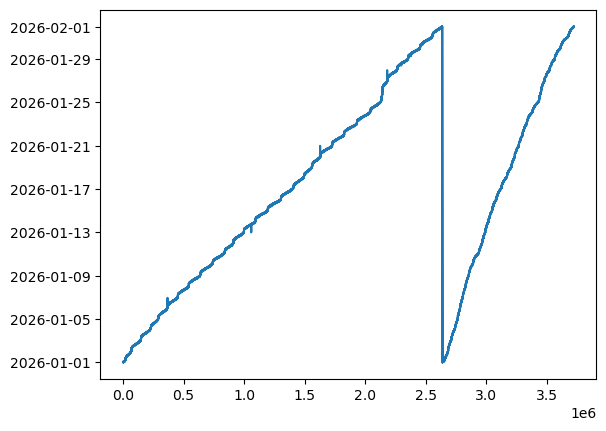

<Axes: >

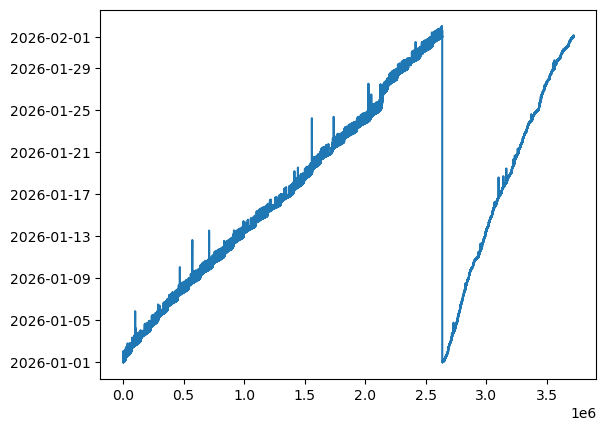

In [10]:
df['tpep_pickup_datetime'].is_monotonic_increasing
df['tpep_pickup_datetime'].plot.line()

plt.show()

df['tpep_dropoff_datetime'].is_monotonic_increasing
df['tpep_dropoff_datetime'].plot.line()

In [11]:
df[df['tpep_pickup_datetime'] > df['tpep_pickup_datetime'].shift(-1)]
df.iloc[0:5]
df = df.sort_values(by = ['tpep_pickup_datetime'])
df

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
980,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.0,0.01,2.0,N,132,264,3,-70.00,0.0,-0.5,0.00,0.0,-1.0,-71.50,0.0,0.00,0.00
981,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.0,0.01,2.0,N,132,264,3,70.00,0.0,0.5,0.00,0.0,1.0,71.50,0.0,0.00,0.00
1404,2,2025-12-31 23:57:54,2026-01-01 00:09:36,1.0,2.00,1.0,N,164,144,1,12.80,1.0,0.5,2.00,0.0,1.0,20.55,2.5,0.00,0.75
5181,2,2025-12-31 23:58:45,2026-01-01 00:07:12,1.0,1.68,1.0,N,113,4,1,10.70,1.0,0.5,2.00,0.0,1.0,18.45,2.5,0.00,0.75
982,2,2025-12-31 23:58:58,2026-01-01 01:04:39,2.0,40.14,3.0,N,132,1,2,167.20,1.0,0.0,0.00,27.0,1.0,198.70,0.0,1.75,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3721510,1,2026-01-31 23:59:57,2026-02-01 00:22:36,NaN,4.00,NaN,None,114,142,0,31.34,0.0,0.5,0.00,0.0,1.0,51.93,NaN,NaN,0.75
3721802,1,2026-01-31 23:59:58,2026-02-01 00:36:43,NaN,10.30,NaN,None,146,228,0,35.57,0.0,0.5,0.00,0.0,1.0,42.96,NaN,NaN,0.00
3724117,2,2026-01-31 23:59:59,2026-02-01 00:05:10,NaN,0.49,NaN,None,114,144,0,29.20,0.0,0.5,0.00,0.0,1.0,33.95,NaN,NaN,0.75
3721547,2,2026-01-31 23:59:59,2026-02-01 00:19:28,NaN,5.77,NaN,None,152,161,0,22.19,0.0,0.5,0.00,0.0,1.0,26.94,NaN,NaN,0.75


In [12]:
wrong = df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']
df[wrong]
df[df['trip_distance'] == 16.5]
df = df[~wrong]

In [13]:
df['passenger_count'].value_counts()

passenger_count
1.0    2150993
2.0     334370
3.0      72864
4.0      49738
0.0      14787
5.0       9184
6.0       4887
8.0          4
7.0          2
9.0          1
Name: count, dtype: int64

In [14]:
print(df['trip_distance'].value_counts())

q1_dist = df['trip_distance'].quantile(0.25)
q3_dist = df['trip_distance'].quantile(0.75)
iqr_dist = q3_dist - q1_dist
dist_outlier = (df['trip_distance'] > (q3_dist + 1.5 * iqr_dist)) | (df['trip_distance'] < (q1_dist - 1.5 * iqr_dist))
df[dist_outlier]

df[df['trip_distance'] > 300]['trip_distance'].min()

df = df[~(df['trip_distance'] > 300)]

df[df['trip_distance'] > 250]['trip_distance'].min() 
df[df['trip_distance'] == 257.24] 

trip_distance
0.00         125738
0.90          36863
0.80          36695
1.00          36018
1.10          35504
              ...  
57.10             1
84.57             1
155023.86         1
34.44             1
236183.06         1
Name: count, Length: 4777, dtype: int64


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
1245274,2,2026-01-15 15:01:51,2026-01-15 20:19:09,1.0,257.24,5.0,N,215,265,1,490.0,0.0,0.0,0.0,7.46,1.0,498.46,0.0,0.0,0.0


In [15]:
df[(df['trip_distance'] == 0) & (df['fare_amount'] == 0)] 
df[(df['trip_distance'] == 0) & (df['fare_amount'] != 0)] 


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
2640643,2,2026-01-01 00:00:56,2026-01-01 00:17:26,NaN,0.0,NaN,None,42,212,0,20.00,0.00,0.5,0.00,0.0,1.0,21.50,NaN,NaN,0.00
4288,2,2026-01-01 00:01:11,2026-01-01 00:01:17,1.0,0.0,5.0,N,143,143,1,33.45,0.00,0.0,0.00,0.0,1.0,36.95,2.5,0.0,0.00
1641,2,2026-01-01 00:01:45,2026-01-01 00:01:56,3.0,0.0,5.0,N,107,107,1,200.00,0.00,0.0,51.06,0.0,1.0,255.31,2.5,0.0,0.75
2409,2,2026-01-01 00:04:20,2026-01-01 00:14:33,4.0,0.0,1.0,N,66,66,1,10.00,1.00,0.5,0.00,0.0,1.0,12.50,0.0,0.0,0.00
5003,1,2026-01-01 00:05:53,2026-01-01 00:06:51,1.0,0.0,1.0,N,161,161,3,3.00,4.25,0.5,0.00,0.0,1.0,8.75,2.5,0.0,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3721560,2,2026-01-31 23:58:11,2026-01-31 23:59:54,NaN,0.0,NaN,None,164,164,0,42.21,0.00,0.5,0.00,0.0,1.0,46.96,NaN,NaN,0.75
2636255,2,2026-01-31 23:58:35,2026-01-31 23:58:43,1.0,0.0,1.0,N,107,107,2,3.00,1.00,0.5,0.00,0.0,1.0,8.75,2.5,0.0,0.75
2633117,2,2026-01-31 23:59:15,2026-01-31 23:59:27,1.0,0.0,1.0,N,229,229,4,3.00,1.00,0.5,0.00,0.0,1.0,8.75,2.5,0.0,0.75
2633116,2,2026-01-31 23:59:15,2026-01-31 23:59:27,1.0,0.0,1.0,N,229,229,4,-3.00,-1.00,-0.5,0.00,0.0,-1.0,-8.75,-2.5,0.0,-0.75


In [16]:
df['RatecodeID'].value_counts()
df[df['RatecodeID'] == 99]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
3727,1,2026-01-01 00:00:31,2026-01-01 01:29:55,1.0,22.2,99.0,N,228,180,1,52.50,0.0,0.5,0.00,0.00,0.0,53.00,0.0,0.0,0.00
4729,1,2026-01-01 00:02:49,2026-01-01 02:13:12,1.0,23.2,99.0,N,215,247,1,45.50,0.0,0.5,0.00,0.00,0.0,46.00,0.0,0.0,0.00
3404,1,2026-01-01 00:02:57,2026-01-01 00:46:08,1.0,10.2,99.0,N,76,55,1,37.50,0.0,0.5,0.00,0.00,0.0,38.00,0.0,0.0,0.00
3892,1,2026-01-01 00:03:10,2026-01-01 00:26:32,1.0,3.5,99.0,N,41,69,1,23.50,0.0,0.5,0.00,0.00,0.0,24.00,0.0,0.0,0.00
3585,1,2026-01-01 00:03:39,2026-01-01 01:04:41,1.0,8.2,99.0,N,188,115,1,41.50,0.0,0.5,0.00,13.88,0.0,55.88,0.0,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2634665,2,2026-01-31 23:51:59,2026-01-31 23:57:43,1.0,0.0,99.0,N,100,264,1,17.84,0.0,0.5,1.45,0.00,1.0,24.04,2.5,0.0,0.75
2634734,1,2026-01-31 23:56:32,2026-02-01 00:11:59,1.0,1.8,99.0,N,76,76,1,19.50,0.0,0.5,0.00,0.00,0.0,20.00,0.0,0.0,0.00
2632549,2,2026-01-31 23:57:58,2026-02-01 00:38:15,1.0,0.0,99.0,N,249,138,1,45.42,0.0,0.5,0.00,0.00,1.0,50.17,2.5,0.0,0.75
2634217,1,2026-01-31 23:59:13,2026-02-01 01:01:29,1.0,16.2,99.0,N,38,80,1,51.50,0.0,0.5,0.00,0.00,0.0,52.00,0.0,0.0,0.00


In [17]:
df['store_and_fwd_flag'].astype(str).value_counts()

store_and_fwd_flag
N       2634490
None    1087950
Y          2337
Name: count, dtype: int64

In [18]:
df['PULocationID'].value_counts()
df['DOLocationID'].value_counts()
df['payment_type'].value_counts()

payment_type
1    2249744
0    1087950
2     314042
4      56400
3      16641
Name: count, dtype: int64

In [19]:
df[df['fare_amount'] < 0]


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
980,2,2025-12-31 23:57:29,2025-12-31 23:57:32,2.0,0.01,2.0,N,132,264,3,-70.0,0.0,-0.5,0.0,0.00,-1.0,-71.50,0.0,0.00,0.00
5065,2,2026-01-01 00:01:19,2026-01-01 00:04:08,1.0,0.05,1.0,N,48,163,2,-4.4,-1.0,-0.5,0.0,0.00,-1.0,-10.15,-2.5,0.00,-0.75
428,2,2026-01-01 00:01:24,2026-01-01 00:02:02,1.0,0.03,1.0,N,162,162,4,-3.0,-1.0,-0.5,0.0,0.00,-1.0,-8.75,-2.5,0.00,-0.75
1046,2,2026-01-01 00:01:52,2026-01-01 00:04:22,2.0,0.14,1.0,N,234,234,3,-3.7,-1.0,-0.5,0.0,0.00,-1.0,-9.45,-2.5,0.00,-0.75
1218,2,2026-01-01 00:03:11,2026-01-01 00:06:26,1.0,0.15,1.0,N,249,249,2,-5.1,-1.0,-0.5,0.0,0.00,-1.0,-10.85,-2.5,0.00,-0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2635645,2,2026-01-31 23:56:16,2026-02-01 00:01:47,2.0,0.97,1.0,N,237,237,4,-7.9,-1.0,-0.5,0.0,0.00,-1.0,-12.90,-2.5,0.00,0.00
2636491,2,2026-01-31 23:57:19,2026-02-01 00:39:03,1.0,18.18,2.0,N,132,48,4,-70.0,0.0,-0.5,0.0,-22.46,-1.0,-98.96,-2.5,-1.75,-0.75
2634581,2,2026-01-31 23:58:20,2026-02-01 00:12:30,2.0,0.97,1.0,N,249,113,2,-13.5,-1.0,-0.5,0.0,0.00,-1.0,-19.25,-2.5,0.00,-0.75
2633517,2,2026-01-31 23:59:10,2026-02-01 00:01:38,1.0,0.46,1.0,N,234,113,4,-5.1,-1.0,-0.5,0.0,0.00,-1.0,-10.85,-2.5,0.00,-0.75


In [20]:
df[df['total_amount'] < 0]

total = df[
    [
        'fare_amount',
        'extra',
        'mta_tax',
        'tip_amount',
        'tolls_amount',
        'improvement_surcharge',
        'congestion_surcharge',
        'Airport_fee',
        'cbd_congestion_fee'
    ]
].sum(axis = 1)

df[(df['total_amount'] == total) & (df['total_amount'] < 0)]

inverse = (np.isclose(df['total_amount'], total, atol=0.01) & (df['total_amount'] < 0))

price_cols = [
    'fare_amount',
    'extra',
    'mta_tax',
    'tip_amount',
    'tolls_amount',
    'improvement_surcharge',
    'total_amount',
    'congestion_surcharge',
    'Airport_fee',
    'cbd_congestion_fee'
]

df.loc[inverse, price_cols] = df.loc[inverse, price_cols].abs()

df[df['total_amount'] < 0]


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
24172,2,2026-01-01 10:03:24,2026-01-01 10:28:32,4.0,7.14,1.0,N,48,261,2,-33.1,0.0,-0.5,0.0,0.00,-1.0,-40.35,-2.5,0.0,-0.75
23437,2,2026-01-01 10:32:58,2026-01-01 10:51:06,1.0,4.38,1.0,N,186,88,2,-22.6,0.0,-0.5,0.0,-3.75,-1.0,-33.60,-2.5,0.0,-0.75
26601,2,2026-01-01 11:12:58,2026-01-01 11:35:15,4.0,11.02,1.0,N,239,138,4,-43.6,-5.0,-0.5,0.0,-6.94,-1.0,-62.04,-2.5,0.0,0.00
46268,2,2026-01-01 16:30:20,2026-01-01 17:29:14,2.0,17.07,2.0,N,230,132,3,-70.0,0.0,-0.5,0.0,0.00,-1.0,-77.25,-2.5,0.0,-0.75
49824,2,2026-01-01 17:24:13,2026-01-01 18:03:51,4.0,17.01,4.0,N,164,1,4,-120.6,-2.5,0.0,0.0,-16.06,-1.0,-143.41,0.0,0.0,-0.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2556363,2,2026-01-31 03:05:54,2026-01-31 03:11:25,1.0,1.24,1.0,N,68,230,3,-7.9,-1.0,-0.5,0.0,0.00,-1.0,-16.15,-2.5,0.0,-0.75
2558567,2,2026-01-31 06:23:19,2026-01-31 06:29:46,2.0,0.78,1.0,N,48,246,4,-7.9,-1.0,-0.5,0.0,0.00,-1.0,-16.15,-2.5,0.0,-0.75
2577597,2,2026-01-31 12:31:57,2026-01-31 12:44:04,2.0,1.67,1.0,N,231,68,4,-12.1,0.0,-0.5,0.0,0.00,-1.0,-19.35,-2.5,0.0,-0.75
2601049,2,2026-01-31 17:46:59,2026-01-31 18:14:32,3.0,0.95,1.0,N,48,164,2,-21.9,0.0,-0.5,0.0,0.00,-1.0,-29.15,-2.5,0.0,-0.75


In [21]:
df[price_cols] = df[price_cols].abs()
total = df[
    [
        'fare_amount',
        'extra',
        'mta_tax',
        'tip_amount',
        'tolls_amount',
        'improvement_surcharge',
        'congestion_surcharge',
        'Airport_fee',
        'cbd_congestion_fee'
    ]
].sum(axis = 1)
df['total_amount'] = total

(3724777, 20)

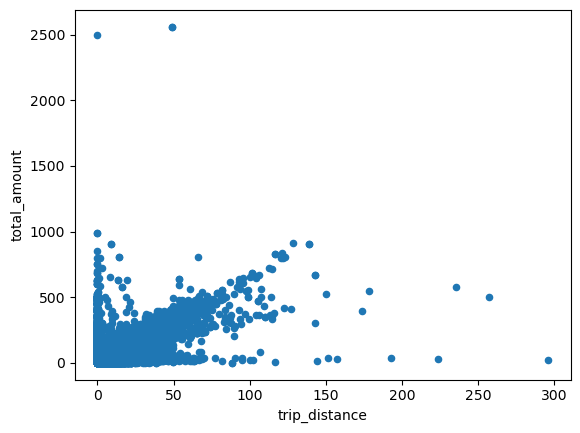

In [22]:
df[['trip_distance', 'total_amount']].plot.scatter(x = 'trip_distance', y = 'total_amount')
df.shape

(3724769, 20)

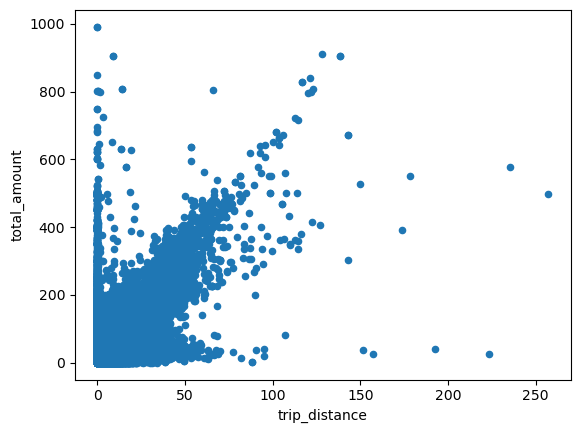

In [23]:
df = df[~(df['total_amount'] > 2000)]
df = df[~((df['total_amount'] < 25) & (df['trip_distance'] > 100))]
df[['trip_distance', 'total_amount']].plot.scatter(x = 'trip_distance', y = 'total_amount')
df.shape

In [24]:
df = df.drop_duplicates()
df.shape
df.isna().sum()

VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count          1087948
trip_distance                  0
RatecodeID               1087948
store_and_fwd_flag       1087948
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge     1087948
Airport_fee              1087948
cbd_congestion_fee             0
dtype: int64